# 04 — Feature Engineering
**Event Recommendation System** · Stage 5

Turn events and interactions into numbers that the models can compare: **event vectors** for content-based filtering, and a sparse **user × event matrix** for SVD.

### Setup (run this first)
- **In Google Colab** this cell downloads the project from GitHub (data + `src/` code) and moves into it.
- **On your own computer** it just moves from `notebooks/` to the project root.

`sys.path.insert(0, "src")` lets us `import recsys` - the small package that holds the reusable code (cleaning, models, metrics). Notebooks *explain* the code; `src/recsys` *stores* it so every notebook uses exactly the same implementation.

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/Abdelrahman2115/recommender-system.git"

if "google.colab" in sys.modules:                       # running inside Google Colab
    if not os.path.exists("/content/recommender-system"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/recommender-system"], check=True)
    os.chdir("/content/recommender-system")
elif os.path.basename(os.getcwd()) == "notebooks":      # running locally from the notebooks folder
    os.chdir("..")

sys.path.insert(0, "src")                               # make `import recsys` work
print("Project root:", os.getcwd())

Project root: /home/claude/recommender-system


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recsys.data import load_clean, temporal_split
from recsys.plotting import set_style, MAIN, TEXT
set_style()

users, events, inter = load_clean()
train, val, test = temporal_split(inter)

## 1. One text document per event ("soup")
TF-IDF works on a single text, so we join everything that describes the event: **category + tags + title + description**. `|` in tags is replaced by a space and everything is lower-cased so "Python" and "python" are the same word.

In [3]:
from recsys.features import event_text

soup = event_text(events)
for i in range(2):
    print(f"event {events.loc[i, 'event_id']}:", soup.iloc[i], "\n")

event 1: education & workshops conversation german language exchange gathering language exchange gathering. a languages event about no experience needed, english, egypt, learn, german, french, session. 

event 2: food & drink coffee barista brewing gathering brewing gathering. a coffee event about barista, brewing, special, premium, for professionals, web development, fun, session, roasting. 



## 2. TF-IDF: which words describe *this* event?
**TF-IDF = Term Frequency × Inverse Document Frequency.**
- **TF** — how often a word appears in this event's text. Frequent here → probably important for this event.
- **IDF** — `log(N / number of events containing the word)`. A word in *every* event ("event", "join us") gets a low IDF; a rare, specific word ("snorkeling") gets a high one.
- Multiply them: the highest scores go to words that are frequent in this event but rare overall — the words that make it distinctive.

Settings we use and why:
| Setting | Value | Why |
|---|---|---|
| `stop_words="english"` | removes "the", "a", "about"… | they carry no topic |
| `ngram_range=(1, 2)` | single words + pairs | keeps phrases like "machine learning", "street food" |
| `min_df=2` | word must appear in ≥2 events | a word seen once cannot make two events similar |
| `sublinear_tf=True` | uses 1 + log(tf) | a word repeated 3× is not 3× more important |

> **Is fitting TF-IDF on all events leakage?** No: TF-IDF only reads the event descriptions, which are public as soon as an event is listed. It never sees who attended what. Leakage is about using *outcomes* (user behaviour) from the future — those only come from the training interactions.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_text = tfidf.fit_transform(soup)          # sparse matrix: one row per event, one column per word/phrase
vocab = np.array(tfidf.get_feature_names_out())
print("TF-IDF matrix:", X_text.shape, f"-> {X_text.nnz / np.prod(X_text.shape):.1%} of cells are non-zero")

# The 6 most distinctive terms of the first event
row = X_text[0].toarray().ravel()
top = row.argsort()[::-1][:6]
pd.DataFrame({"term": vocab[top], "tf-idf": row[top].round(3)})

TF-IDF matrix: (800, 2294) -> 1.1% of cells are non-zero


,term,tf-idf
0,exchange gathering,0.371
1,german,0.244
2,exchange,0.240
3,language,0.240
4,language exchange,0.240
5,gathering language,0.219


## 3. Structured features: category, city, price bucket
Text is not everything. EDA showed that **city** strongly affects attendance and that **price** matters, so we add them as **one-hot** columns (one column per possible value, 1 if the event has it, 0 otherwise). Category gets its own block too, so two events in the same category are similar even if their descriptions share few words.

Price is grouped into buckets first (free / cheap ≤150 / medium ≤400 / expensive EGP).

In [5]:
from recsys.features import price_bucket
from sklearn.preprocessing import OneHotEncoder

print(price_bucket(events).value_counts().to_string(), "\n")
city_onehot = OneHotEncoder().fit_transform(events[["city"]])
print("city one-hot shape:", city_onehot.shape, "| first event's row:", city_onehot[0].toarray().astype(int))

price
medium       295
cheap        218
free         200
expensive     87 

city one-hot shape: (800, 7) | first event's row: [[1 0 0 0 0 0 0]]


## 4. Combining the blocks with weights
We have 4 blocks: **text, category, city, price**. How do we join them fairly?

1. **Normalise each block** to length 1 (L2 norm), so a block with many columns (text) does not dominate just because it is bigger.
2. **Multiply each block by √weight** and stack them side by side.
3. **Normalise the whole vector** again.

Result: the **cosine similarity** of two events equals a *weighted average* of their per-block similarities:

`cos(a, b) = (1.0·cos_text + 0.5·cos_category + 0.5·cos_city + 0.2·cos_price) / 2.2`

That makes the weights easy to explain: text matters most, then category and city, price a little. (These weights are checked on validation data in notebook 05.)

**Cosine similarity** = the cosine of the angle between two vectors: 1 = pointing the same way (very similar), 0 = nothing in common. Because all vectors have length 1, cosine is simply the dot product.

In [6]:
from recsys.features import EventFeaturizer

featurizer = EventFeaturizer(text_weight=1.0, category_weight=0.5, city_weight=0.5, price_weight=0.2)
X = featurizer.fit_transform(events)
print("final event matrix:", X.shape)
print("row lengths (should all be 1):", np.round(np.sqrt(X.multiply(X).sum(axis=1)).A.ravel()[:5], 6))

final event matrix: (800, 2313)
row lengths (should all be 1): [1. 1. 1. 1. 1.]


### 4.1 Verify the weighted-average property numerically

In [7]:
from sklearn.preprocessing import normalize

a, b = 2, 140                                      # rows of event 3 and event 141 (two related events)
blocks = featurizer._blocks(events, fit=False)
per_block = {n: float(normalize(blocks[n][a]).multiply(normalize(blocks[n][b])).sum()) for n in blocks}
w = featurizer.weights
expected = sum(w[n] * per_block[n] for n in w) / sum(w.values())
actual = float(X[a].multiply(X[b]).sum())
print({k: round(v, 3) for k, v in per_block.items()})
print(f"weighted average = {expected:.4f}   cosine of full vectors = {actual:.4f}")

{'text': 0.588, 'category': 1.0, 'city': 1.0, 'price': 1.0}
weighted average = 0.8129   cosine of full vectors = 0.8129


## 5. Do the vectors make sense? Nearest neighbours of an event
A quick sanity check: the events most similar to a given event should be about the same topic, ideally in the same city.

In [8]:
def similar_events(event_id, n=5):
    i = events.index[events["event_id"] == event_id][0]
    sims = (X @ X[i].T).toarray().ravel()           # cosine with every event (rows are unit length)
    order = np.argsort(-sims)[1:n + 1]                # skip the event itself
    out = events.iloc[order][["event_id", "title", "category", "city", "price"]].copy()
    out["similarity"] = sims[order].round(3)
    return out

print("Query:", events.loc[events["event_id"] == 3, ["title", "category", "city", "price"]].to_dict("records")[0])
similar_events(3)

Query: {'title': 'Ethical Hacking Night', 'category': 'Technology', 'city': 'Cairo', 'price': 80.0}


,event_id,title,category,city,price,similarity
140,141,Ethical Hacking Meetup,Technology,Cairo,80.0,0.813
300,301,Privacy Night,Technology,Cairo,110.0,0.807
452,453,Cloud Meetup,Technology,Cairo,130.0,0.774
457,458,Privacy Night,Technology,Cairo,120.0,0.772
740,741,Cloud Workshop,Technology,Cairo,50.0,0.754


### 5.1 How distinct are the categories?
Average cosine similarity between events of each pair of categories. A strong diagonal = categories are well separated; non-zero off-diagonal = some overlap (shared words, same cities).

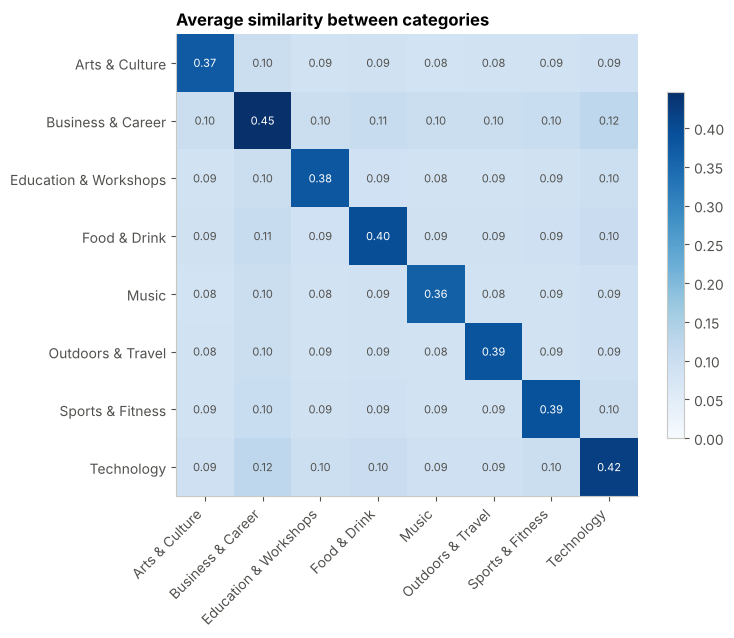

In [9]:
cats = sorted(events["category"].unique())
dense = X.toarray()
sim = np.array([[ (dense[events["category"].values == c1] @ dense[events["category"].values == c2].T).mean()
                  for c2 in cats] for c1 in cats])

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(sim, cmap="Blues", vmin=0, vmax=sim.max())
ax.set_xticks(range(len(cats)), cats, rotation=45, ha="right"); ax.set_yticks(range(len(cats)), cats)
for i in range(len(cats)):
    for j in range(len(cats)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if sim[i, j] > sim.max() * 0.6 else TEXT)
ax.grid(False); ax.set_title("Average similarity between categories")
fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()

## 6. Features for collaborative filtering: the user × event matrix
SVD does not read text. It only needs **who interacted with what, and how strongly**. We build two matrices from the **training interactions only**:

- **Engagement matrix** (for ranking): value = interaction weight (view 1 … attended 4), 0 = no interaction.
- **Rating matrix** (for rating prediction): value = the 1–5 rating; *missing* means unknown.

`scipy.sparse.csr_matrix` stores only the non-zero cells. A dense 2,000 × 800 matrix would hold 1.6 million numbers, almost all zeros.

In [10]:
from scipy.sparse import csr_matrix

u_idx = pd.Series(np.arange(len(users)), index=users["user_id"])       # user_id -> row number
e_idx = pd.Series(np.arange(len(events)), index=events["event_id"])    # event_id -> column number

R = csr_matrix((train["weight"].astype(float),
                (u_idx[train["user_id"]].to_numpy(), e_idx[train["event_id"]].to_numpy())),
               shape=(len(users), len(events)))
print("engagement matrix:", R.shape, f"| non-zero cells: {R.nnz:,} ({R.nnz / np.prod(R.shape):.2%})")
print(f"memory: sparse ≈ {(R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6:.2f} MB vs dense ≈ {np.prod(R.shape) * 8 / 1e6:.1f} MB")

rated = train.dropna(subset=["rating"])
print("\ntraining ratings:", len(rated), "| users with ≥1 rating:", rated["user_id"].nunique(),
      "| events with ≥1 rating:", rated["event_id"].nunique())

engagement matrix: (2000, 800) | non-zero cells: 23,762 (1.49%)
memory: sparse ≈ 0.29 MB vs dense ≈ 12.8 MB

training ratings: 5056 | users with ≥1 rating: 1446 | events with ≥1 rating: 466


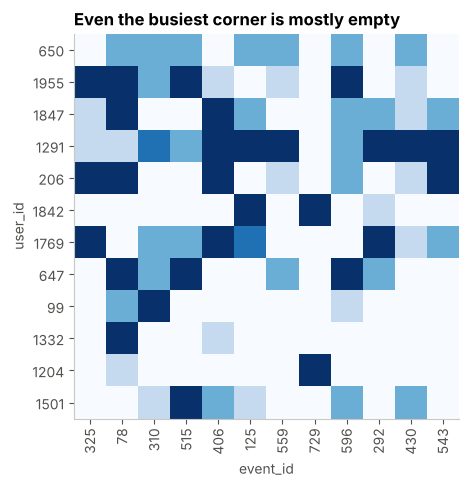

In [11]:
# A small corner of the engagement matrix: the 12 most active users x 12 most popular events
top_u = train["user_id"].value_counts().index[:12]
top_e = train["event_id"].value_counts().index[:12]
corner = R[u_idx[top_u].to_numpy()][:, e_idx[top_e].to_numpy()].toarray()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.imshow(corner, cmap="Blues", vmin=0, vmax=4)
ax.set_xticks(range(12), top_e, rotation=90); ax.set_yticks(range(12), top_u)
ax.set_xlabel("event_id"); ax.set_ylabel("user_id"); ax.grid(False)
ax.set_title("Even the busiest corner is mostly empty")
plt.show()

## Summary
| Feature | Built from | Used by |
|---|---|---|
| TF-IDF text block | category, tags, title, description | Content-Based |
| One-hot category / city / price bucket | event columns | Content-Based |
| Weighted, normalised event vector | all 4 blocks | Content-Based (cosine similarity) |
| Engagement matrix (weights 1–4) | **training** interactions | SVD for ranking |
| Rating matrix (1–5) | **training** ratings | SVD for rating prediction |

User profiles (the user's side of content-based filtering) are built from these event vectors in the next notebook.

### Interview questions for this stage
- *Explain TF-IDF in one sentence.* — It scores a word highly when it is frequent in this document but rare across all documents.
- *Why normalise the blocks before combining them?* — Otherwise the block with the most columns or largest values dominates the similarity, regardless of how important it actually is.
- *Why a sparse matrix?* — 97% of the cells are zero; storing only non-zero values saves memory and makes multiplication much faster.

**Next:** `05_content_based.ipynb`.